# **Imports**

Import all the libraries you need for your project. Google Drive mounting code is provided if you plan to use Colab.

In [2]:
# from google.colab import drive
# drive.mount('/content/drive')

In [3]:
import torch

# Check that this environment can use my GPU.
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

GPU available: True
NVIDIA GeForce RTX 4090 Laptop GPU


In [4]:

from pathlib import Path
import json
import random
import time
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms, models
# I use these to check accuracy for each class and count the mistakes.
from sklearn.metrics import classification_report, confusion_matrix
from IPython.display import display, Markdown

# Using the same seed makes my split and starting weights easier to repeat.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    # Set the GPU seed too if there is a GPU.
    torch.cuda.manual_seed_all(SEED)
# A GPU is faster, but the code can also use the CPU.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using:', device)


Using: cuda


# **1. Load Dataset**
The Stanford Dataset is provided in ```torchvision.datasets```. However, you must code your own Dataset class to load the dataset.

You will need to create your inherit from ```Dataset``` class to load the dataset and overload the ```___init__()```, ```__len__()```, and ```__getitem__()``` functions.

You will find the [following link](https://pytorch.org/tutorials/beginner/data_loading_tutorial.html) useful to help create the dataset class.

Please also create another function or method in the class: ```show_imgs()``` to help visualize the data. Similar to Phase 1 and 2, you need to display random images and label. Please display 3-5 unique classes.

In [5]:

# I made my own Dataset instead of using torchvision's car dataset.
class CarDataSet(Dataset):
    def __init__(self, images_path, annotations_path, transform=None,
                 class_to_idx=None, image_col=None, label_col=None,
                 csv_header='infer', csv_names=None):
        # Keep the folder and transform so I can use them when loading an image.
        self.images_path = Path(images_path)
        self.transform = transform
        # Read labels as strings so IDs such as 001 do not lose their zeros.
        self.annotations = pd.read_csv(annotations_path, dtype=str,
                                       header=csv_header, names=csv_names)
        self.annotations.columns = self.annotations.columns.str.strip()
        if self.annotations.empty:
            raise ValueError('The annotation CSV has no image rows.')
        # Recognize common column names, but ask for a choice if it is unclear.
        def choose_column(chosen, choices, kind):
            if chosen is not None:
                if chosen not in self.annotations.columns:
                    raise ValueError(f'{chosen!r} is missing from the CSV.')
                return chosen
            matches = [c for c in self.annotations.columns if c.lower() in choices]
            if len(matches) != 1:
                raise ValueError(f'Set {kind}_col explicitly. CSV columns: '
                                 f'{self.annotations.columns.tolist()}')
            return matches[0]
        self.image_col = choose_column(image_col,
            ('filename', 'file_name', 'image', 'image_path', 'path', 'fname'), 'image')
        self.label_col = choose_column(label_col,
            ('make', 'label', 'class', 'class_id', 'class_name', 'target', 'car_make'), 'label')
        # Missing labels or file names would give wrong training examples.
        needed = self.annotations[[self.image_col, self.label_col]]
        if needed.isna().any().any() or needed.apply(lambda col: col.str.strip().eq('')).any().any():
            raise ValueError('Some rows have an empty image name or label.')
        self.annotations[self.label_col] = self.annotations[self.label_col].str.strip()
        labels = self.annotations[self.label_col].tolist()
        if class_to_idx is None:
            # Turn the training labels into consecutive numbers starting at zero.
            names = sorted(set(labels))
            self.class_to_idx = {name: i for i, name in enumerate(names)}
        else:
            # Validation and test labels must use exactly the training label order.
            self.class_to_idx = dict(class_to_idx)
        if set(self.class_to_idx.values()) != set(range(len(self.class_to_idx))):
            raise ValueError('Class indices must be consecutive numbers starting at zero.')
        unknown = set(labels) - set(self.class_to_idx)
        if unknown:
            raise ValueError(f'These labels were not in training: {sorted(unknown)}')
        self.classes = sorted(self.class_to_idx, key=self.class_to_idx.get)
        self.targets = [self.class_to_idx[label] for label in labels]
        # Check the image paths now so a missing file does not stop a later epoch.
        self.paths = [self.images_path / str(name).strip().replace('\\', '/')
                      for name in self.annotations[self.image_col]]
        missing = [str(p) for p in self.paths if not p.is_file()]
        if missing:
            raise FileNotFoundError(f'{len(missing)} images are missing. First: {missing[0]}')
        if len({p.resolve() for p in self.paths}) != len(self.paths):
            raise ValueError('The CSV repeats an image path. Check it before splitting.')

    def __len__(self):
        # There is one example for each row in the CSV.
        return len(self.targets)

    def __getitem__(self, index):
        # RGB makes grayscale pictures work with the three-channel network too.
        with Image.open(self.paths[index]) as picture:
            image = picture.convert('RGB')
        if self.transform is not None:
            # Apply the training changes or the plain evaluation transform.
            image = self.transform(image)
        return image, self.targets[index]

# The template uses both names, so I make them refer to the same class.
CarsDataset = CarDataSet


In [6]:
# This repository stores its annotations in MATLAB files instead of CSV files.
# I convert them once so my own Dataset can still read ordinary CSV rows.
from scipy.io import loadmat

def convert_car_annotations(annotations_path, metadata_path, output_csv):
    # The metadata gives the real name for each of the 196 class numbers.
    metadata = loadmat(metadata_path, squeeze_me=True, struct_as_record=False)
    class_names = [str(name) for name in np.atleast_1d(metadata['class_names'])]
    annotations = loadmat(annotations_path, squeeze_me=True, struct_as_record=False)
    rows = []
    for annotation in np.atleast_1d(annotations['annotations']):
        if not hasattr(annotation, 'class'):
            # The devkit also has an unlabeled test file, which I cannot score.
            raise ValueError('Use cars_test_annos_withlabels.mat for labeled test data.')
        # MATLAB uses class IDs from 1 to 196, while PyTorch needs 0 to 195.
        label = int(getattr(annotation, 'class')) - 1
        if not 0 <= label < len(class_names):
            raise ValueError('An annotation has a class ID outside the metadata range.')
        rows.append(dict(filename=str(annotation.fname), class_id=label,
                         class_name=class_names[label]))
    # Keep the original annotation order so image names and labels stay matched.
    table = pd.DataFrame(rows)
    output_csv = Path(output_csv)
    output_csv.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(output_csv, index=False)
    return class_names

# I already extracted the dataset, so I only need its folder path here.
DATA_ROOT = Path(r'C:/Users/13079/EEC_174Lab/Lab3/StanfordCars-Dataset-main/stanford_cars')
# Check the two image folders and the three label files before loading them.
required_paths = ['cars_train', 'cars_test', 'devkit/cars_meta.mat',
                  'devkit/cars_train_annos.mat', 'cars_test_annos_withlabels.mat']
for name in required_paths:
    found = (DATA_ROOT / name).is_dir() if name in ('cars_train', 'cars_test') else (DATA_ROOT / name).is_file()
    print(name, ':', found)
    if not found:
        raise FileNotFoundError(f'Check DATA_ROOT. Missing: {DATA_ROOT / name}')
metadata_path = DATA_ROOT / 'devkit/cars_meta.mat'

# Keep the small generated CSV files in my results folder, separate from the images.
results_dir = Path('./phase3_results')
results_dir.mkdir(exist_ok=True)
train_annotations_path = results_dir / 'train_annotations.csv'
repository_classes = convert_car_annotations(DATA_ROOT / 'devkit/cars_train_annos.mat',
                                             metadata_path, train_annotations_path)
# Prepare the public test CSV too, but do not use it to choose training settings.
public_test_annotations_path = results_dir / 'test_annotations.csv'
convert_car_annotations(DATA_ROOT / 'cars_test_annos_withlabels.mat',
                        metadata_path, public_test_annotations_path)
# Save the original class order instead of sorting the car names differently.
repository_class_to_idx = {name: i for i, name in enumerate(repository_classes)}
pd.DataFrame(dict(class_id=range(len(repository_classes)),
                  class_name=repository_classes)).to_csv(results_dir / 'class_names.csv', index=False)
print('Prepared CSV annotations for', len(repository_classes), 'car classes.')

# Load the Data
train_images_path = DATA_ROOT / 'cars_train'
public_test_images_path = DATA_ROOT / 'cars_test'
# If the TA supplies a validation CSV, put its paths here instead of None.
# Otherwise I hold out 20% of each training class for validation.
val_images_path = None
val_annotations_path = None
# The converted CSV uses the original 196 car classes, not just the makes.
IMAGE_COL = 'filename'
LABEL_COL = 'class_name'
# For a CSV without a header, use CSV_HEADER=None and provide CSV_NAMES.
CSV_HEADER = 'infer'
CSV_NAMES = None
csv_options = dict(image_col=IMAGE_COL, label_col=LABEL_COL,
                   csv_header=CSV_HEADER, csv_names=CSV_NAMES)
# These are the ImageNet numbers used by the pretrained ResNet.
IMAGE_MEAN = (0.485, 0.456, 0.406)
IMAGE_STD = (0.229, 0.224, 0.225)
# Mild crops, flips, and color changes give training a little more variety.
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
    transforms.ToTensor(), transforms.Normalize(IMAGE_MEAN, IMAGE_STD)
])
# Validation uses the same plain preprocessing every time.
eval_transform = models.ResNet50_Weights.IMAGENET1K_V2.transforms()
all_train_data = CarDataSet(train_images_path, train_annotations_path,
                            transform=train_transform, class_to_idx=repository_class_to_idx, **csv_options)
classes = all_train_data.classes
class_to_idx = all_train_data.class_to_idx
num_classes = len(classes)
if num_classes < 2:
    raise ValueError('Classification needs at least two classes.')
if (val_images_path is None) != (val_annotations_path is None):
    raise ValueError('Provide both validation paths, or leave both as None.')
if val_annotations_path is not None:
    # Use the separate validation data if it was provided by the TA.
    train_data = all_train_data
    val_data = CarDataSet(val_images_path, val_annotations_path,
        transform=eval_transform, class_to_idx=class_to_idx, **csv_options)
    if {p.resolve() for p in all_train_data.paths} & {p.resolve() for p in val_data.paths}:
        raise ValueError('Training and validation share an image path.')
    train_indices = list(range(len(train_data)))
    val_indices = None
else:
    # Split each class separately so every class is in both parts.
    rng = np.random.default_rng(SEED)
    train_indices, val_indices = [], []
    targets = np.array(all_train_data.targets)
    for label in range(num_classes):
        indices = rng.permutation(np.flatnonzero(targets == label))
        if len(indices) < 2:
            raise ValueError(f'Class {classes[label]} needs at least two images.')
        count = min(len(indices) - 1, max(1, round(0.2 * len(indices))))
        val_indices.extend(indices[:count].tolist())
        train_indices.extend(indices[count:].tolist())
    # This second view uses plain images for validation, without random changes.
    plain_data = CarDataSet(train_images_path, train_annotations_path,
        transform=eval_transform, class_to_idx=class_to_idx, **csv_options)
    train_data = Subset(all_train_data, train_indices)
    val_data = Subset(plain_data, val_indices)
# The template calls this test_data, but I use it as validation during training.
test_data = val_data
# Batch Size
batch_size = 32
loader_options = dict(batch_size=batch_size, num_workers=0,
                      pin_memory=(device.type == 'cuda'))
# Shuffle training batches, while keeping validation order fixed.
# Import to Dataloaders
train_loader = DataLoader(train_data, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), **loader_options)
val_loader = DataLoader(val_data, shuffle=False, **loader_options)
test_loader = val_loader
# Save outputs locally, as suggested in the lab slides.
results_dir = Path('./phase3_results')
results_dir.mkdir(exist_ok=True)
split_info = dict(seed=SEED, train_indices=train_indices, val_indices=val_indices,
                  train_csv=str(train_annotations_path),
                  val_csv=str(val_annotations_path) if val_annotations_path else None)
(results_dir / 'split.json').write_text(json.dumps(split_info, indent=2))
print('Train:', len(train_data), '| Validation:', len(val_data), '| Classes:', num_classes)
print('Target column:', all_train_data.label_col, '| Labels:', classes)


cars_train : True
cars_test : True
devkit/cars_meta.mat : True
devkit/cars_train_annos.mat : True
cars_test_annos_withlabels.mat : True
Prepared CSV annotations for 196 car classes.
Train: 6509 | Validation: 1635 | Classes: 196
Target column: class_name | Labels: ['AM General Hummer SUV 2000', 'Acura RL Sedan 2012', 'Acura TL Sedan 2012', 'Acura TL Type-S 2008', 'Acura TSX Sedan 2012', 'Acura Integra Type R 2001', 'Acura ZDX Hatchback 2012', 'Aston Martin V8 Vantage Convertible 2012', 'Aston Martin V8 Vantage Coupe 2012', 'Aston Martin Virage Convertible 2012', 'Aston Martin Virage Coupe 2012', 'Audi RS 4 Convertible 2008', 'Audi A5 Coupe 2012', 'Audi TTS Coupe 2012', 'Audi R8 Coupe 2012', 'Audi V8 Sedan 1994', 'Audi 100 Sedan 1994', 'Audi 100 Wagon 1994', 'Audi TT Hatchback 2011', 'Audi S6 Sedan 2011', 'Audi S5 Convertible 2012', 'Audi S5 Coupe 2012', 'Audi S4 Sedan 2012', 'Audi S4 Sedan 2007', 'Audi TT RS Coupe 2012', 'BMW ActiveHybrid 5 Sedan 2012', 'BMW 1 Series Convertible 2012', 

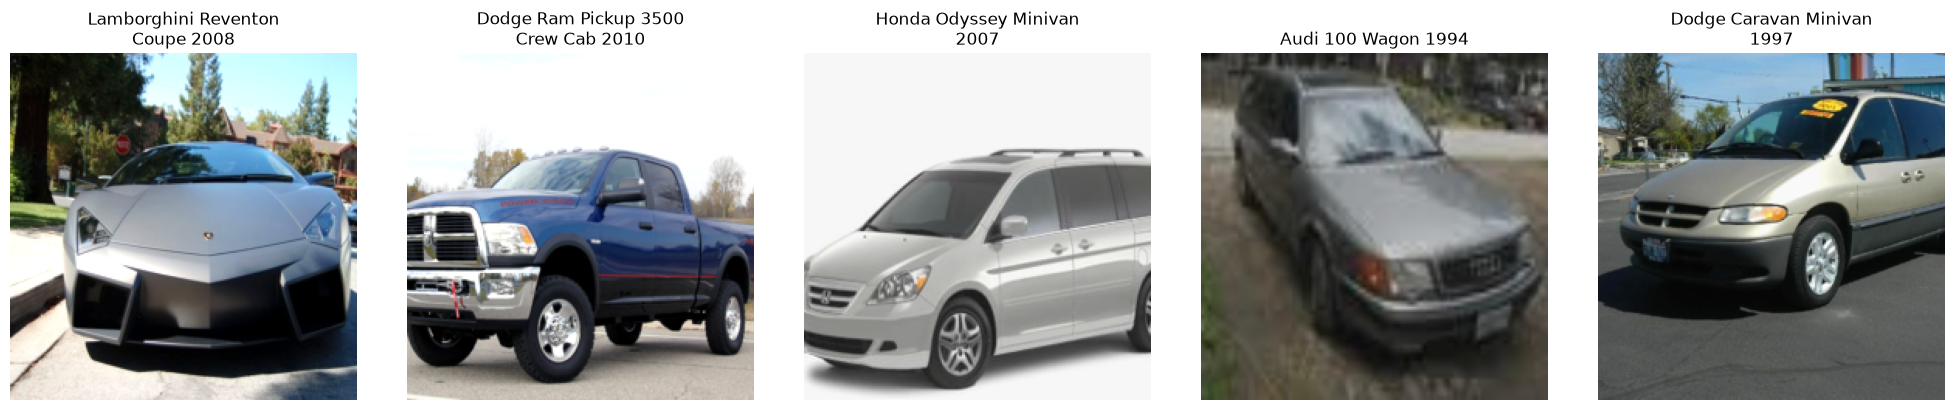

In [7]:
# Undo normalization so the pictures have their normal colors in the plot.
def image_for_plot(image):
    mean = torch.tensor(IMAGE_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGE_STD).view(3, 1, 1)
    return (image.detach().cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

def show_imgs(dataset, class_names, count=5):
    # Find the labels without having to open every image first.
    if isinstance(dataset, Subset):
        targets = np.array(dataset.dataset.targets)[dataset.indices]
    else:
        targets = np.array(dataset.targets)
    rng = np.random.default_rng(SEED)
    unique = np.unique(targets)
    chosen = rng.choice(unique, size=min(count, len(unique)), replace=False)
    fig, axes = plt.subplots(1, len(chosen), figsize=(4 * len(chosen), 4), squeeze=False)
    for ax, label in zip(axes.flat, chosen):
        # Pick one random picture from each chosen class.
        index = int(rng.choice(np.flatnonzero(targets == label)))
        image, _ = dataset[index]
        ax.imshow(image_for_plot(image))
        ax.set_title(textwrap.fill(class_names[label], 24))
        ax.axis('off')
    fig.tight_layout()
    plt.show()

# Show five different classes, or all classes if the data has fewer than five.
show_imgs(train_data, classes)


# **2. Define your Model Architecture**

It is up to you to decide which model you use. You can create your own CNN or use transfer learning.

In [8]:
# Model definition
def build_vehicle_model(num_classes, pretrained=False):
    # Reuse ImageNet features, like the transfer learning in Phase 2.
    weights = models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
    model = models.resnet50(weights=weights)
    # Replace the ImageNet output layer with one score for each car label.
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model
# ResNet50 is a larger starting model than the ResNet18 used in Phase 2.
# I fine-tune all layers so the features can adjust to car pictures.
# Load Model onto GPU
vehicle_classifier = build_vehicle_model(num_classes, pretrained=True).to(device)
print('Output classes:', vehicle_classifier.fc.out_features)
print('Trainable parameters:', sum(p.numel() for p in vehicle_classifier.parameters()))


Output classes: 196
Trainable parameters: 23909636


# **3. Define Optimizer, Scheduler, Loss, etc.**

You chose the loss function and optimizer.

In [9]:
# Loss Function
# Cross entropy takes raw scores and compares them with the correct class number.
loss_function = nn.CrossEntropyLoss()
# One epoch means going through all my training images once.
num_epochs = 25
# I stop if validation does not get better for this many epochs.
patience = 7
# The pretrained layers already know some useful image features.
backbone_lr = 0.0001
# The new final layer starts from scratch, so I let it learn faster.
classifier_lr = 0.001
# This gives large weights a small penalty to help reduce overfitting.
weight_decay = 0.0001
# Optimizer
# The old features get smaller updates than the new output layer.
backbone = [p for name, p in vehicle_classifier.named_parameters()
            if not name.startswith('fc.')]
optimizer = torch.optim.AdamW([
    {'params': backbone, 'lr': backbone_lr},
    {'params': vehicle_classifier.fc.parameters(), 'lr': classifier_lr}
], weight_decay=weight_decay)
# Gradually lower the learning rates so later updates are smaller.
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
weights_path = results_dir / 'vehicle_classifier.pth'
# Save the settings with the model so I can explain the actual run later.
run_config = dict(model='resnet50', weights='IMAGENET1K_V2', epochs=num_epochs,
    patience=patience, batch_size=batch_size, backbone_lr=backbone_lr,
    classifier_lr=classifier_lr, weight_decay=weight_decay,
    optimizer='AdamW', scheduler='CosineAnnealingLR', seed=SEED)


# **4. Train your Network**

Feel free to use your `train()` from either Phase 1 or Phase 2, whichever you feel is a better choice to understand training to tune it better. Please make sure to plot your learning curves, for both loss and accuracy! Again, this can be per iterations or epoch depending on what you see fit. You will need to save your model as `.pth` file! [This link](https://pytorch.org/tutorials/beginner/saving_loading_models.html) will be useful.

In [10]:

# Train Network
def evaluate(model, loader, loss_fn, device):
    # Testing should not change weights or batch normalization statistics.
    was_training = model.training
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            # Put the images and labels on the same device as the model.
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss_sum += loss_fn(outputs, labels).item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    model.train(was_training)
    if total == 0:
        raise ValueError('The evaluation loader has no images.')
    return loss_sum / total, 100 * correct / total

def train(model, train_loader, val_loader, loss_fn, optimizer, scheduler,
          num_epochs, patience, device, weights_path):
    # Keep one set of measurements for each epoch, like Phase 2.
    history = {key: [] for key in ('train_loss', 'val_loss',
        'train_accuracy', 'val_accuracy', 'seconds', 'learning_rates')}
    best_accuracy, best_loss, best_epoch, waiting = -1.0, float('inf'), 0, 0
    for epoch in range(num_epochs):
        if device.type == 'cuda':
            # Wait for the GPU so the timer measures the full epoch.
            torch.cuda.synchronize()
        start = time.perf_counter()
        model.train()
        loss_sum, correct, total = 0.0, 0, 0
        history['learning_rates'].append([group['lr'] for group in optimizer.param_groups])
        for images, labels in train_loader:
            # Clear old gradients before doing this batch's forward pass.
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            # Backpropagation finds the gradients, then AdamW updates the weights.
            loss.backward()
            optimizer.step()
            # Weight the loss by batch size since the last batch may be smaller.
            loss_sum += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        val_loss, val_accuracy = evaluate(model, val_loader, loss_fn, device)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        # Store the real results for the curves and report.
        for key, value in [('train_loss', loss_sum / total),
            ('train_accuracy', 100 * correct / total), ('val_loss', val_loss),
            ('val_accuracy', val_accuracy), ('seconds', time.perf_counter() - start)]:
            history[key].append(value)
        improved = val_accuracy > best_accuracy or (val_accuracy == best_accuracy and val_loss < best_loss)
        if improved:
            # Save the best validation model, with its labels and preprocessing.
            best_accuracy, best_loss, best_epoch, waiting = val_accuracy, val_loss, epoch + 1, 0
            checkpoint = dict(
                model_state_dict={k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                class_to_idx=class_to_idx, classes=classes, config=run_config,
                image_col=all_train_data.image_col, label_col=all_train_data.label_col,
                csv_header=CSV_HEADER, csv_names=CSV_NAMES,
                preprocessing=dict(resize=232, crop=224, mean=list(IMAGE_MEAN), std=list(IMAGE_STD)),
                best_epoch=best_epoch, val_accuracy=best_accuracy, val_loss=best_loss)
            torch.save(checkpoint, weights_path)
        else:
            # Stop after several epochs without a better validation result.
            waiting += 1
        scheduler.step()
        history['best_epoch'] = best_epoch
        # Save history every epoch so I still have it if a later epoch is interrupted.
        (results_dir / 'history.json').write_text(json.dumps(history, indent=2))
        print(f'Epoch {epoch + 1}/{num_epochs} | Train loss {loss_sum / total:.4f}, '
              f'acc {100 * correct / total:.2f}% | Val loss {val_loss:.4f}, '
              f'acc {val_accuracy:.2f}% | {history["seconds"][-1]:.1f}s')
        if waiting >= patience:
            print('Stopping because validation has stopped improving.')
            break
    # Bring back the best epoch instead of just using the last epoch.
    checkpoint = torch.load(weights_path, map_location='cpu', weights_only=True)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f'Best epoch: {best_epoch}, validation accuracy: {best_accuracy:.2f}%')
    return history

# This starts the actual training. A CUDA GPU is recommended for this part.
history = train(vehicle_classifier, train_loader, val_loader, loss_function,
                optimizer, scheduler, num_epochs, patience, device, weights_path)


Epoch 1/25 | Train loss 3.6825, acc 20.92% | Val loss 1.8540, acc 51.62% | 121.5s
Epoch 2/25 | Train loss 0.8861, acc 75.36% | Val loss 1.1650, acc 66.61% | 115.5s
Epoch 3/25 | Train loss 0.3121, acc 91.75% | Val loss 0.9695, acc 73.46% | 118.4s
Epoch 4/25 | Train loss 0.1439, acc 96.27% | Val loss 0.9557, acc 75.54% | 122.2s
Epoch 5/25 | Train loss 0.0936, acc 97.68% | Val loss 0.9250, acc 76.57% | 121.9s
Epoch 6/25 | Train loss 0.0596, acc 98.60% | Val loss 0.8865, acc 76.82% | 120.4s
Epoch 7/25 | Train loss 0.0428, acc 99.08% | Val loss 0.8381, acc 77.86% | 124.8s
Epoch 8/25 | Train loss 0.0311, acc 99.40% | Val loss 0.8420, acc 78.35% | 225.7s
Epoch 9/25 | Train loss 0.0305, acc 99.26% | Val loss 0.9435, acc 76.94% | 122.1s
Epoch 10/25 | Train loss 0.0336, acc 99.17% | Val loss 0.9514, acc 77.92% | 121.2s
Epoch 11/25 | Train loss 0.0218, acc 99.49% | Val loss 0.9230, acc 78.41% | 124.9s
Epoch 12/25 | Train loss 0.0164, acc 99.68% | Val loss 0.8792, acc 78.90% | 124.2s
Epoch 13/25 |

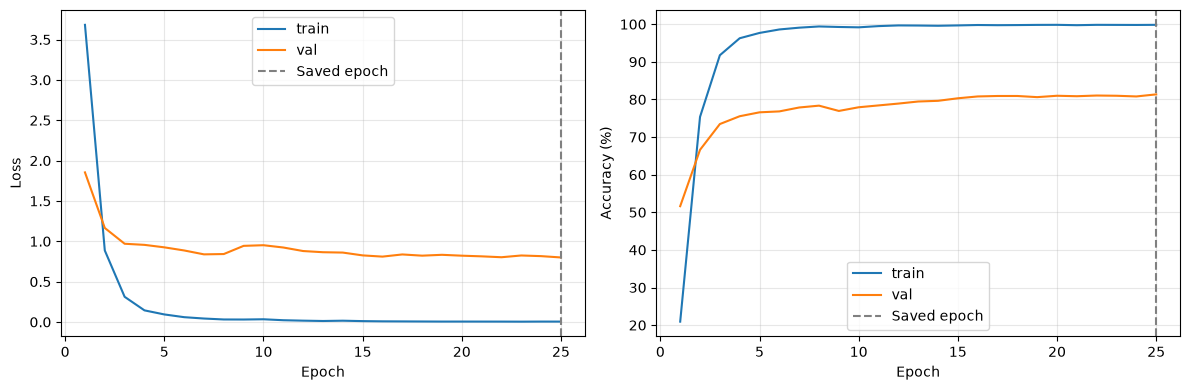

In [11]:
# Plot learning curves
# Put loss and accuracy side by side so I can compare train and validation.
epochs = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, ylabel in zip(axes, ('loss', 'accuracy'), ('Loss', 'Accuracy (%)')):
    for split in ('train', 'val'):
        # Each point is the average for a full epoch.
        ax.plot(epochs, history[f'{split}_{metric}'], label=split)
    ax.axvline(history['best_epoch'], color='gray', linestyle='--', label='Saved epoch')
    ax.set(xlabel='Epoch', ylabel=ylabel)
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(results_dir / 'learning_curves.png', dpi=160)
plt.show()


# **5. Evaluate**

Now we will evaluate on validation set. The TA's will run your model on the hold-out test set for your final grade.

## **5.1 Average and Per-class Accuracy**

Feel free to use `test_accuracy()` here to get accuracy. You also must show per-class accuracy. You can write your own accuracy function to get per class accuracy or use `classification_report` from `sklearn`.

In [12]:
def collect_predictions(model, loader, device):
    # Keep only numbers instead of storing every image in memory.
    model.eval()
    true_labels, predicted_labels, confidences = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            # Softmax turns the scores into probabilities for displaying confidence.
            probabilities = model(images.to(device)).softmax(dim=1)
            confidence, predictions = probabilities.max(dim=1)
            true_labels.extend(labels.tolist())
            predicted_labels.extend(predictions.cpu().tolist())
            confidences.extend(confidence.cpu().tolist())
    return np.array(true_labels), np.array(predicted_labels), np.array(confidences)

# Check the saved best model on validation. The TA's test set stays separate.
val_loss, val_accuracy = evaluate(vehicle_classifier, val_loader, loss_function, device)
y_true, y_pred, confidences = collect_predictions(vehicle_classifier, val_loader, device)
print(f'Validation loss: {val_loss:.4f} | Average accuracy: {val_accuracy:.2f}%')
per_class_rows = []
for label, name in enumerate(classes):
    # Per-class accuracy means correct predictions divided by images of that class.
    mask = y_true == label
    support = int(mask.sum())
    accuracy = 100 * (y_pred[mask] == label).mean() if support else float('nan')
    per_class_rows.append(dict(class_name=name, images=support, accuracy_percent=accuracy))
per_class_table = pd.DataFrame(per_class_rows)
display(per_class_table)
per_class_table.to_csv(results_dir / 'per_class_accuracy.csv', index=False)
# Include every class even if a validation split has no examples of one class.
print(classification_report(y_true, y_pred, labels=list(range(num_classes)),
                            target_names=classes, zero_division=0))
predictions_table = pd.DataFrame(dict(true_index=y_true, predicted_index=y_pred,
                                     confidence=confidences))
predictions_table.to_csv(results_dir / 'validation_predictions.csv', index=False)


Validation loss: 0.7997 | Average accuracy: 81.35%


,class_name,images,accuracy_percent
0,AM General Hummer SUV 2000,9,77.777778
1,Acura RL Sedan 2012,6,33.333333
2,Acura TL Sedan 2012,9,100.000000
3,Acura TL Type-S 2008,8,75.000000
4,Acura TSX Sedan 2012,8,87.500000
...,...,...,...
191,Volkswagen Beetle Hatchback 2012,9,100.000000
192,Volvo C30 Hatchback 2012,8,100.000000
193,Volvo 240 Sedan 1993,9,100.000000
194,Volvo XC90 SUV 2007,9,88.888889


                                                        precision    recall  f1-score   support

                            AM General Hummer SUV 2000       0.88      0.78      0.82         9
                                   Acura RL Sedan 2012       1.00      0.33      0.50         6
                                   Acura TL Sedan 2012       0.82      1.00      0.90         9
                                  Acura TL Type-S 2008       0.86      0.75      0.80         8
                                  Acura TSX Sedan 2012       0.78      0.88      0.82         8
                             Acura Integra Type R 2001       0.88      0.78      0.82         9
                              Acura ZDX Hatchback 2012       0.86      0.75      0.80         8
              Aston Martin V8 Vantage Convertible 2012       0.75      0.67      0.71         9
                    Aston Martin V8 Vantage Coupe 2012       0.50      0.50      0.50         8
                  Aston Martin Virage C

## **5.2 Confusion Matrix**

Please plot the confusion matrix with all classess. Please make this visually readable.

Full class names: phase3_results/confusion_matrix.pdf
Class ID key: phase3_results/class_names.csv


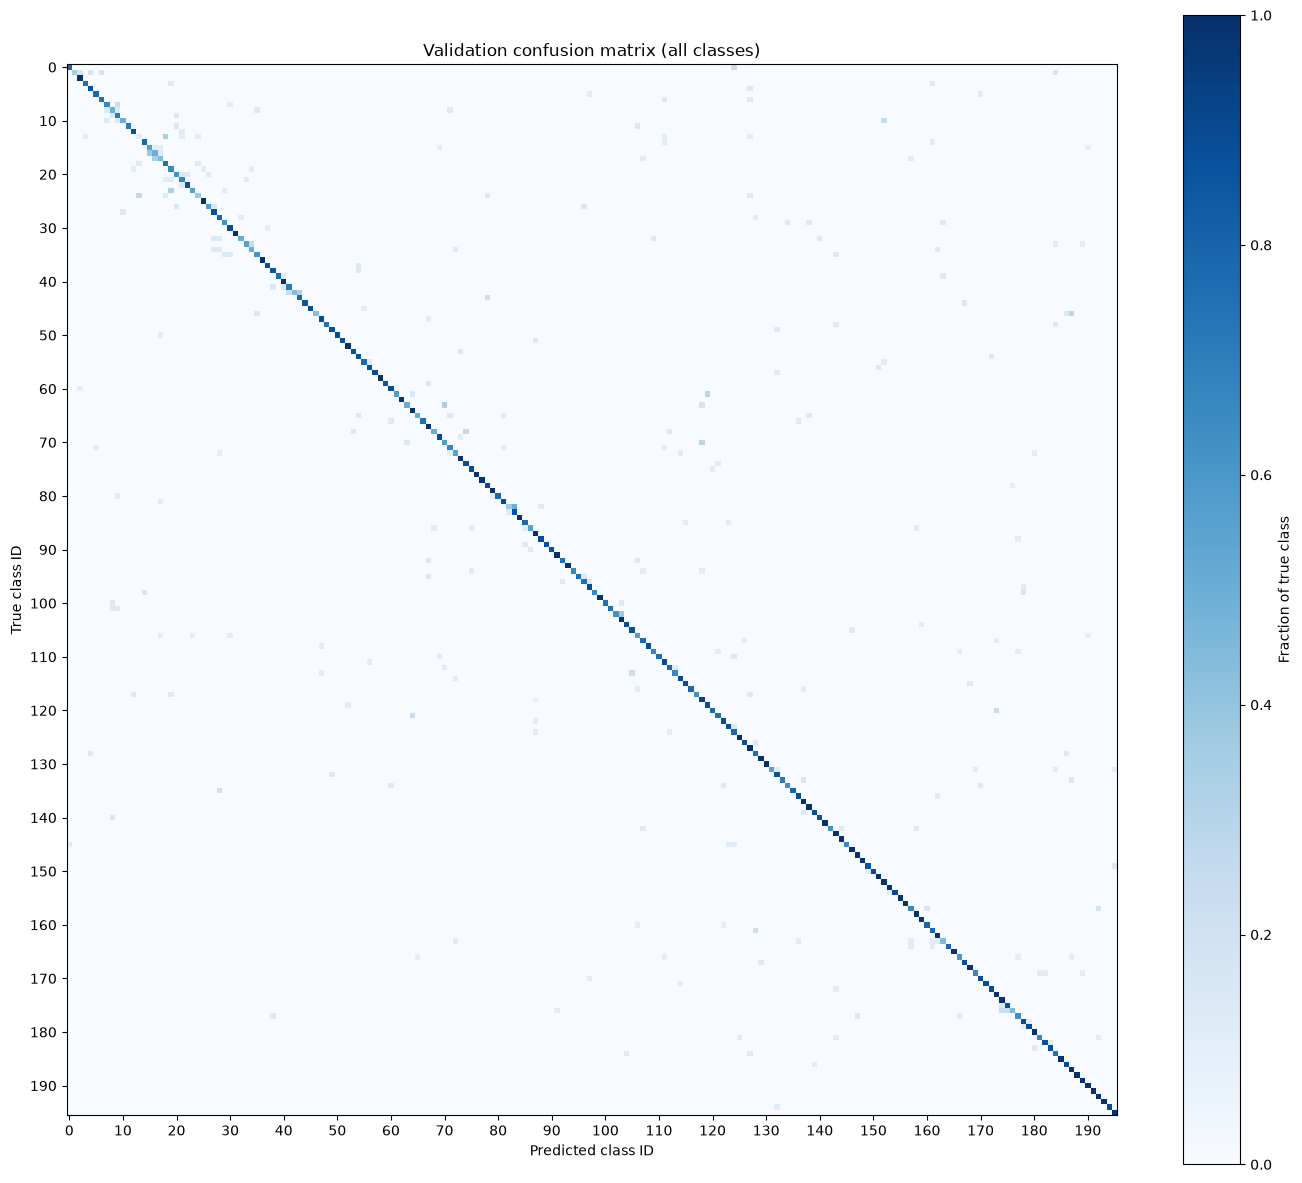

In [13]:
# Rows are the true classes and columns are the model's predictions.
cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
support = cm.sum(axis=1, keepdims=True)
cm_normalized = np.divide(cm, support, out=np.zeros_like(cm, dtype=float), where=support != 0)
# Save counts too, since row percentages hide how many pictures each class has.
pd.DataFrame(cm, index=classes, columns=classes).to_csv(results_dir / 'confusion_counts.csv')
# Make a large saved figure so all labels can be read by zooming in.
side = max(10, num_classes * 0.32)
fig, ax = plt.subplots(figsize=(side, side))
image = ax.imshow(cm_normalized, cmap='Blues', vmin=0, vmax=1)
ticks = np.arange(num_classes)
ax.set_xticks(ticks, labels=classes, rotation=90, fontsize=8)
ax.set_yticks(ticks, labels=classes, fontsize=8)
ax.set(xlabel='Predicted label', ylabel='True label', title='Validation confusion matrix (row fractions)')
if num_classes <= 30:
    # With fewer classes there is enough space to write the counts in the boxes.
    for row in range(num_classes):
        for col in range(num_classes):
            ax.text(col, row, str(cm[row, col]), ha='center', va='center', fontsize=7,
                    color='white' if cm_normalized[row, col] > 0.5 else 'black')
fig.colorbar(image, ax=ax, fraction=0.035, label='Fraction of true class')
fig.tight_layout()
fig.savefig(results_dir / 'confusion_matrix.pdf', bbox_inches='tight')
if num_classes > 30:
    # The PDF has every name. This smaller view is easier to see in the notebook.
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(14, 12))
    image = ax.imshow(cm_normalized, cmap='Blues', vmin=0, vmax=1)
    # These numbers match the class_id column in class_names.csv.
    ticks = np.arange(0, num_classes, 10)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set(xlabel='Predicted class ID', ylabel='True class ID',
           title='Validation confusion matrix (all classes)')
    fig.colorbar(image, ax=ax, label='Fraction of true class')
    fig.tight_layout()
    print('Full class names: phase3_results/confusion_matrix.pdf')
    print('Class ID key: phase3_results/class_names.csv')
plt.show()


## **5.3 Check Model Inference**

Please write a function, `show_predictions()` which will show:


1.   The top 5 confidenct predicted images with an example each.
2.   The bottom 5 confident predicted images, with an example each.

For each image, show the true label, what your model predicted and with what confidence.



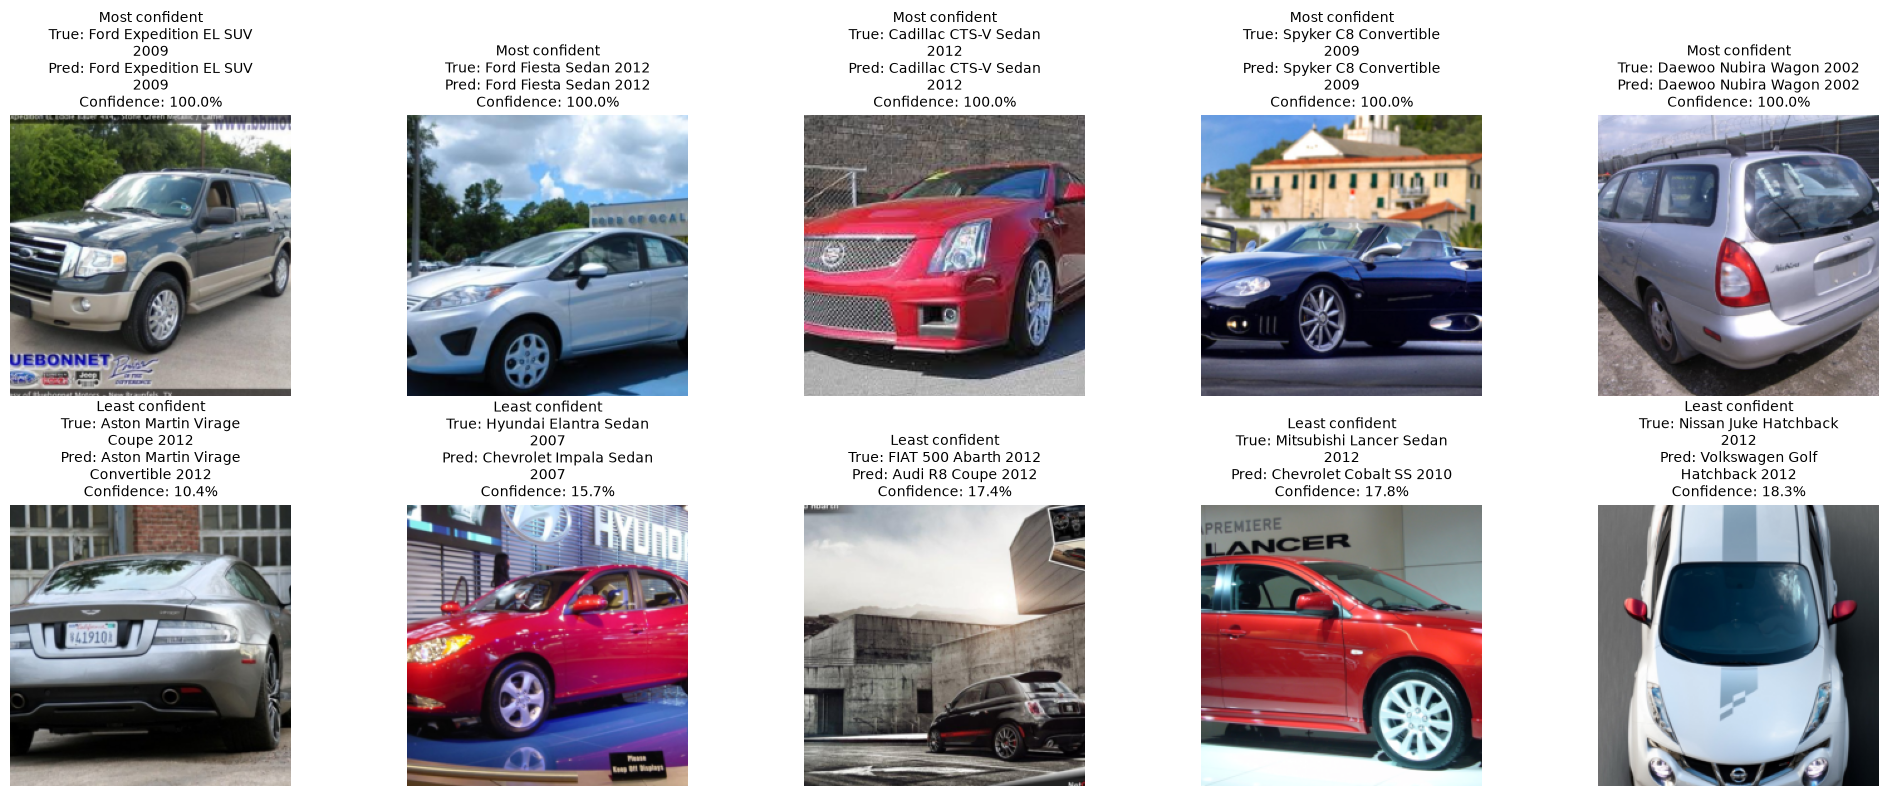

Best epoch: **25**. Validation accuracy: **81.35%**. Validation loss: **0.7997**. Epochs run: **25**. Training plus validation time: **54.4 minutes**.

Saved-epoch training accuracy: 99.83
Saved-epoch training loss: 0.0048


,class_name,images,accuracy_percent
13,Audi TTS Coupe 2012,9,11.111111
1,Acura RL Sedan 2012,6,33.333333
24,Audi TT RS Coupe 2012,8,37.500000
82,Dodge Caliber Wagon 2012,8,37.500000
46,Buick Regal GS 2012,7,42.857143


Dodge Caliber Wagon 2012 -> Dodge Caliber Wagon 2007: 4 images
Ferrari 458 Italia Convertible 2012 -> Ferrari 458 Italia Coupe 2012: 3 images
Bentley Continental GT Coupe 2007 -> Bentley Continental Flying Spur Sedan 2007: 3 images
Audi TTS Coupe 2012 -> Audi TT Hatchback 2011: 3 images
Audi S4 Sedan 2007 -> Audi S6 Sedan 2011: 3 images


In [14]:
def show_predictions(model, dataset, class_names, device, count=5):
    # Make an ordered loader so each prediction matches its dataset index.
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    actual, predicted, confidence = collect_predictions(model, loader, device)
    if len(actual) == 0:
        raise ValueError('There are no images to show.')
    count = min(count, len(actual))
    order = np.argsort(confidence, kind='stable')
    groups = [('Most confident', order[::-1][:count]), ('Least confident', order[:count])]
    fig, axes = plt.subplots(2, count, figsize=(4 * count, 8), squeeze=False)
    for row, (heading, indices) in enumerate(groups):
        for ax, index in zip(axes[row], indices):
            # Show this example, its real label, prediction, and top probability.
            image, _ = dataset[int(index)]
            ax.imshow(image_for_plot(image))
            title = (heading + '\nTrue: ' + class_names[actual[index]] +
                     '\nPred: ' + class_names[predicted[index]] +
                     f'\nConfidence: {100 * confidence[index]:.1f}%')
            ax.set_title('\n'.join(textwrap.fill(line, 30) for line in title.split('\n')),
                         fontsize=10)
            ax.axis('off')
    fig.tight_layout()
    fig.savefig(results_dir / 'confidence_examples.png', dpi=160, bbox_inches='tight')
    plt.show()
    # A confident prediction can still be wrong, so I do not filter out mistakes.
    return actual, predicted, confidence

show_predictions(vehicle_classifier, val_data, classes, device)

# Print actual run numbers to help me finish the results part of my report.
best = history['best_epoch'] - 1
display(Markdown(
    f"Best epoch: **{best + 1}**. Validation accuracy: **{val_accuracy:.2f}%**. "
    f"Validation loss: **{val_loss:.4f}**. Epochs run: **{len(history['train_loss'])}**. "
    f"Training plus validation time: **{sum(history['seconds']) / 60:.1f} minutes**."))
print('Saved-epoch training accuracy:', round(history['train_accuracy'][best], 2))
print('Saved-epoch training loss:', round(history['train_loss'][best], 4))
display(per_class_table.sort_values('accuracy_percent').head(5))
# Sort wrong predictions by count to find which classes the model confuses most.
pairs = [(int(cm[i, j]), classes[i], classes[j]) for i in range(num_classes)
         for j in range(num_classes) if i != j and cm[i, j] > 0]
for count, actual, predicted in sorted(pairs, reverse=True)[:5]:
    print(f'{actual} -> {predicted}: {count} images')


## **6. Report**

Please write a report discussing all your choices and procedure to implement your vehicle classifier. In your report, include all your choices (i.e. hyperparameters, lr, models, loss, optimizer) and explain why you made those choices to achieve your performance. Your report must be thorough and comprehensive, please discuss fully how you were able to obtain a high performance. Please also include an analysis of your model, whether it may be overfitting or underfitting or fitting well and what you may have done to further improve your performance.

We used transfer learning for this part, like in Phase 2, and chose ResNet50 with ImageNet V2 weights because it has already learned useful features from many pictures. The last layer was changed to give 196 outputs, one for each car class. All layers were allowed to train so the features could adjust to the car pictures.

The Stanford Cars dataset came from the GitHub repository because the normal download was broken. The MATLAB annotations were converted to CSV files, and the custom CarDataSet class loads the image names, labels, and RGB pictures. The class numbers were changed from 1–196 to 0–195 for PyTorch, keeping the same label order across datasets. An 80/20 split within each training class gave 6,509 training images and 1,635 validation images. Seed 42 makes the split repeatable. We kept the separate public test images out of training and model selection.

Training uses random crops to 224 × 224 pixels, horizontal flips, and small color changes to give the model more variety. Validation uses a resize to 232 pixels on the shorter side followed by a 224 × 224 center crop. Both use ImageNet normalization to match the pretrained model.

We chose a batch size of 32 and cross-entropy loss because each image has one correct class. AdamW uses a learning rate of 0.0001 for the pretrained layers and 0.001 for the new final layer, allowing the new layer to learn faster. Weight decay is 0.0001 to help reduce overfitting, while a cosine scheduler gradually lowers the learning rates. Training allows 25 epochs, with early stopping after 7 epochs without validation improvement. The model with the highest validation accuracy is saved as a .pth file, using lower validation loss to break ties.

The run completed all 25 epochs and took about 54.4 minutes. The best model came from epoch 25, reaching 81.35% validation accuracy and 0.7997 validation loss, with 1,330 correct predictions out of 1,635 images. These results describe the internal validation split; the public test set and the TA’s test set were not evaluated here.

The learning curves show quick improvement at first, followed by slower progress. Training accuracy increased from 20.92% to 99.83%, while validation accuracy increased from 51.62% to 81.35%. Training loss dropped from 3.6825 to 0.0048, and validation loss dropped from 1.8540 to 0.7997. We noticed that the final accuracy gap of about 18.49 percentage points suggests some overfitting. Training and validation use different transforms and measurement conditions, but the model still fits the training images much better. However, validation continued improving overall and reached its best results at epoch 25, so there was no steady decline from longer training.

Performance varied between classes. Acura TL Sedan 2012 had 9 out of 9 correct predictions, while Audi TTS Coupe 2012 had only 1 out of 9 correct, or 11.11%. Acura RL Sedan 2012 reached 33.33%. These percentages should be interpreted carefully because each class has few validation images. The macro and weighted F1 scores were both about 0.81.

The confusion matrix has a strong diagonal, but some similar cars were mixed up. Four Dodge Caliber Wagon 2012 images were predicted as the 2007 version, and three Ferrari 458 Italia Convertible 2012 images were predicted as the coupe version. This suggests that small differences in year and body type remain difficult to recognize. All five most confident examples were correct, with confidence rounded to 100.0%, while the five least confident examples were wrong, with scores between 10.4% and 18.3%. These examples are useful, but high confidence does not guarantee a correct prediction.

To improve the model, we could try freezing some pretrained layers or increasing weight decay to reduce overfitting. A larger image size might help the model recognize smaller details. More epochs could also be tested because validation was still improving, but any changes should be compared using validation results. We have not tested these improvements yet.

# **7. Loading your model code**

Please provide code to initialize your model, and code to load the model. Please call your model `vehicle_classifier`. This is so we can easily run your model.

Please also provide here your CarDataSet class and loader with option to add a path for the test data images and csv annotations.

You do not need to do anythig else, this code will be used by TAs to load and run your model to grade on test set.

[This link](https://pytorch.org/tutorials/beginner/saving_loading_models.html) will be useful.

In [15]:
# This section can run in a fresh kernel without running training first.
from pathlib import Path
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

# I made my own Dataset instead of using torchvision's car dataset.
class CarDataSet(Dataset):
    def __init__(self, images_path, annotations_path, transform=None,
                 class_to_idx=None, image_col=None, label_col=None,
                 csv_header='infer', csv_names=None):
        # Keep the folder and transform so I can use them when loading an image.
        self.images_path = Path(images_path)
        self.transform = transform
        # Read labels as strings so IDs such as 001 do not lose their zeros.
        self.annotations = pd.read_csv(annotations_path, dtype=str,
                                       header=csv_header, names=csv_names)
        self.annotations.columns = self.annotations.columns.str.strip()
        if self.annotations.empty:
            raise ValueError('The annotation CSV has no image rows.')
        # Recognize common column names, but ask for a choice if it is unclear.
        def choose_column(chosen, choices, kind):
            if chosen is not None:
                if chosen not in self.annotations.columns:
                    raise ValueError(f'{chosen!r} is missing from the CSV.')
                return chosen
            matches = [c for c in self.annotations.columns if c.lower() in choices]
            if len(matches) != 1:
                raise ValueError(f'Set {kind}_col explicitly. CSV columns: '
                                 f'{self.annotations.columns.tolist()}')
            return matches[0]
        self.image_col = choose_column(image_col,
            ('filename', 'file_name', 'image', 'image_path', 'path', 'fname'), 'image')
        self.label_col = choose_column(label_col,
            ('make', 'label', 'class', 'class_id', 'class_name', 'target', 'car_make'), 'label')
        # Missing labels or file names would give wrong training examples.
        needed = self.annotations[[self.image_col, self.label_col]]
        if needed.isna().any().any() or needed.apply(lambda col: col.str.strip().eq('')).any().any():
            raise ValueError('Some rows have an empty image name or label.')
        self.annotations[self.label_col] = self.annotations[self.label_col].str.strip()
        labels = self.annotations[self.label_col].tolist()
        if class_to_idx is None:
            # Turn the training labels into consecutive numbers starting at zero.
            names = sorted(set(labels))
            self.class_to_idx = {name: i for i, name in enumerate(names)}
        else:
            # Validation and test labels must use exactly the training label order.
            self.class_to_idx = dict(class_to_idx)
        if set(self.class_to_idx.values()) != set(range(len(self.class_to_idx))):
            raise ValueError('Class indices must be consecutive numbers starting at zero.')
        unknown = set(labels) - set(self.class_to_idx)
        if unknown:
            raise ValueError(f'These labels were not in training: {sorted(unknown)}')
        self.classes = sorted(self.class_to_idx, key=self.class_to_idx.get)
        self.targets = [self.class_to_idx[label] for label in labels]
        # Check the image paths now so a missing file does not stop a later epoch.
        self.paths = [self.images_path / str(name).strip().replace('\\', '/')
                      for name in self.annotations[self.image_col]]
        missing = [str(p) for p in self.paths if not p.is_file()]
        if missing:
            raise FileNotFoundError(f'{len(missing)} images are missing. First: {missing[0]}')
        if len({p.resolve() for p in self.paths}) != len(self.paths):
            raise ValueError('The CSV repeats an image path. Check it before splitting.')

    def __len__(self):
        # There is one example for each row in the CSV.
        return len(self.targets)

    def __getitem__(self, index):
        # RGB makes grayscale pictures work with the three-channel network too.
        with Image.open(self.paths[index]) as picture:
            image = picture.convert('RGB')
        if self.transform is not None:
            # Apply the training changes or the plain evaluation transform.
            image = self.transform(image)
        return image, self.targets[index]

# The template uses both names, so I make them refer to the same class.
CarsDataset = CarDataSet

def build_vehicle_model(num_classes, pretrained=False):
    # Reuse ImageNet features, like the transfer learning in Phase 2.
    weights = models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
    model = models.resnet50(weights=weights)
    # Replace the ImageNet output layer with one score for each car label.
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model
# paths
# These defaults use the public test split. The TA can supply their own paths.
# Their CSV labels must describe the same 196 car classes as training.
# If their labels are numeric, convert them using class_names.csv first.
# Use the same downloaded dataset when running this section by itself.
test_images_path = Path(r'C:/Users/13079/EEC_174Lab/Lab3/StanfordCars-Dataset-main/stanford_cars/cars_test')
test_annotations_path = Path('./phase3_results/test_annotations.csv')
weights_path = Path('./phase3_results/vehicle_classifier.pth')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# The checkpoint contains weights, label order, and preprocessing settings.
checkpoint = torch.load(weights_path, map_location='cpu', weights_only=True)
preprocessing = checkpoint['preprocessing']
test_transform = transforms.Compose([
    transforms.Resize(preprocessing['resize']),
    transforms.CenterCrop(preprocessing['crop']),
    transforms.ToTensor(),
    transforms.Normalize(preprocessing['mean'], preprocessing['std'])
])
# Change these column settings only if the test CSV uses different headers.
test_image_col = checkpoint['image_col']
test_label_col = checkpoint['label_col']
test_dataset = CarsDataset(test_images_path, test_annotations_path,
    transform=test_transform, class_to_idx=checkpoint['class_to_idx'],
    image_col=test_image_col, label_col=test_label_col,
    csv_header=checkpoint['csv_header'], csv_names=checkpoint['csv_names'])
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)
# Define model
# No ImageNet download is needed since I load all the trained weights below.
vehicle_classifier = build_vehicle_model(len(checkpoint['classes']), pretrained=False)
# load your weights (from weights_path)
vehicle_classifier.load_state_dict(checkpoint['model_state_dict'])
vehicle_classifier = vehicle_classifier.to(device)
vehicle_classifier.eval()
print('Loaded vehicle_classifier with', len(checkpoint['classes']), 'classes.')


Loaded vehicle_classifier with 196 classes.


___
___
# End of Phase 3 😊🥳